# 02 Designs

Station layouts and deployment schedule. Trilliums stay out for the whole deployment, at sites chosen to balance
hypocentre location and matrix imaging. Nodes are deployed in phases:
a wide reconnaissance grid over the area where the deep conductor may be, then a dense rolling deployment centred on
the target found in phase 1. Static designs are kept for comparison. The existing Mercury stations at Rotokawa and
Ngā Tamariki (`data/RTK_NTM_Station_Coordinates.dat`) are already in the ground, so they record for the whole
deployment in every design, like the Trilliums.

Inputs: `data/site.json`, `data/RTK_NTM_Station_Coordinates.dat`, water polygons. Output: `data/stations.csv`, `data/designs.json`

In [1]:
# --- Imports ---
import json

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt

In [10]:
# --- Site  ---
site = json.load(open("../data/site.json"))
DRILL = (site["drill_site"]["lon"], site["drill_site"]["lat"])
KY = 111.32
KX = KY * np.cos(np.radians(DRILL[1]))
P2_SEARCH_R = 4.0   

AZ = 120 # long axis of node layouts: across the 30 deg fault strike


def to_ll(x, y):
    """km east and north of the drill site -> lon, lat."""
    return DRILL[0] + np.asarray(x) / KX, DRILL[1] + np.asarray(y) / KY


def km(lon, lat):
    """lon, lat -> km east and north of the drill site."""
    return (np.asarray(lon) - DRILL[0]) * KX, (np.asarray(lat) - DRILL[1]) * KY


def layout(along, across, centre=(0, 0)):
    """Points given along/across the AZ axis (km), turned onto the map and moved to centre. Returns (x, y)."""
    a = np.radians(AZ)
    s, t = np.ravel(along), np.ravel(across)
    return centre[0] + s * np.sin(a) - t * np.cos(a), centre[1] + s * np.cos(a) + t * np.sin(a)


def grid(nx, ny, dx, dy, centre=(0, 0)):
    """nx x ny grid with spacing dx (along AZ) and dy (across), centred on centre."""
    s, t = np.meshgrid((np.arange(nx) - (nx - 1) / 2) * dx, (np.arange(ny) - (ny - 1) / 2) * dy)
    return layout(s, t, centre)


water = pd.concat([gpd.read_file("../data/nz-lake-polygons-topo-150k.shp"),
                   gpd.read_file("../data/nz-river-polygons-topo-150k.shp")]).to_crs(4326)
water = water.cx[DRILL[0] - 0.3:DRILL[0] + 0.3, DRILL[1] - 0.3:DRILL[1] + 0.3].union_all()


def keep(x, y):
    """Drop stations in water."""
    ok = ~shapely.contains_xy(water, *to_ll(x, y))
    return np.asarray(x)[ok], np.asarray(y)[ok]


# --- Existing Mercury stations (Rotokawa and Nga Tamariki), NZTM2000 easting/northing in metres ---
merc = []
for line in open("../data/RTK_NTM_Station_Coordinates.dat").read().splitlines()[2:]:
    parts = line.split()
    if len(parts) < 4:
        continue
    merc.append((" ".join(parts[:-3]), parts[-3], float(parts[-2]), float(parts[-1])))
mercury = pd.DataFrame(merc, columns=["field", "name", "e", "n"])
ll = gpd.GeoSeries(gpd.points_from_xy(mercury.e, mercury.n), crs=2193).to_crs(4326)
mercury["x"], mercury["y"] = km(ll.x, ll.y)

In [3]:
# --- Equipment ---
N_NODES = 20
# Trillium sites (km east, north of the drill site). Chosen by optimising a 50/50 mix of hypocentre location error
# (P+S, 1D Sewell et al. 2017 model, trial events 2-8 km deep within 5 km) and matrix-imaging focal-spot size
# (station pairs over the BDT top, 4-6.5 km deep within 6 km), with the Mercury stations fixed. At least 1 km from
# each other and from every Mercury station, clear of water.
TRILLIUM_SITES = [
    ( 0.00, -2.80),
    ( 1.20, -4.80),
    ( 2.80, -3.20),
    ( 6.00, -6.00),
    ( 1.60, -1.20),
    ( 4.40, -3.20),
    ( 4.40, -0.40),
    ( 8.40,  0.40),
    ( 5.20,  0.80),
    ( 4.00,  3.60),
    (-4.80,  1.20),
    (-8.00,  0.00),
    (-4.40, -0.80),
    (-3.60, -2.00),
    (-6.40, -5.20),
    (-3.20, -3.60),
    (-1.20, -2.00),
    (-1.20, -5.20),
    (-0.40, -8.40),
]

TARGET_CENTRE = (0.0, 0.0)  # km from drill site.
TARGET_ALONG, TARGET_ACROSS = 8.0, 6.0 

# --- Phase 1: wide reconnaissance grid over the target area ---
P1_NX, P1_NY = 5, 4 # 20 nodes
P1_DAYS = 84  # recording time before moving to phase 2. placeholder

# --- Phase 2: dense rolling deployment over the target found in phase 1 ---
P2_CENTRE = (0.0, 0.0) # chosen after phase 1; varied in the tests
P2_SPACING = 0.6 # node spacing (km)
P2_PATCH_DAYS = 42 # each patch out for 6 weeks
P2_PATCHES = 6

DEPLOY_DAYS = 3 * 365                  # total deployment

In [4]:
# --- Trillium sites ---
tx, ty = np.array(TRILLIUM_SITES).T

In [11]:
# --- Phase 1: wide grid spanning the target area ---
p1 = grid(P1_NX, P1_NY, TARGET_ALONG / (P1_NX - 1), TARGET_ACROSS / (P1_NY - 1), TARGET_CENTRE)

# --- Phase 2: a 15 x 8 dense grid cut into six 5 x 4 patches, visited in a snake order ---
along = (np.arange(15) - 7) * P2_SPACING
acr = (np.arange(8) - 3.5) * P2_SPACING
order = [(i, j) for i in range(3) for j in (range(2) if i % 2 == 0 else reversed(range(2)))]
p2 = [layout(*np.meshgrid(along[i * 5:(i + 1) * 5], acr[j * 4:(j + 1) * 4]), P2_CENTRE) for i, j in order]

# --- Static comparison designs ---
k = np.arange(N_NODES)
static = {"grid": grid(5, 4, 0.5, 0.5),
          "wide grid": grid(5, 4, 1.5, 1.5),
          "spiral": (4.5 * np.sqrt((k + 0.5) / N_NODES) * np.sin(np.radians(137.5 * k)),
                     4.5 * np.sqrt((k + 0.5) / N_NODES) * np.cos(np.radians(137.5 * k)))}

In [7]:
rows = []


def add(kind, xy):
    """Add stations (minus any in water) to the table and return their ids."""
    start = len(rows)
    rows.extend((kind, "", *p) for p in zip(*keep(*xy)))
    return list(range(start, len(rows)))


trill = add("trillium", (tx, ty))
if len(trill) < len(tx):
    print(f"warning: {len(tx) - len(trill)} Trillium site(s) fall in water and were dropped")

# Existing Mercury stations: kept as they are (no water check), out for the whole deployment
start = len(rows)
rows.extend(("mercury", r.name, r.x, r.y) for r in mercury.itertuples())
existing = list(range(start, len(rows)))

designs = {"trillium only": [dict(start=0, end=DEPLOY_DAYS, stations=[])]}
for name, xy in static.items():
    designs[name] = [dict(start=0, end=DEPLOY_DAYS, stations=add("node", xy))]

phases = [dict(start=0, end=P1_DAYS, stations=add("node", p1))]
for q, xy in enumerate(p2):
    t0 = P1_DAYS + q * P2_PATCH_DAYS
    phases.append(dict(start=t0, end=t0 + P2_PATCH_DAYS, stations=add("node", xy)))
designs["phased"] = phases

# --- Phase 2 station bank: every spot a phase 2 node could occupy ---
nb_i = int(np.ceil(P2_SEARCH_R / P2_SPACING)) + 7      # half-count along AZ (rolling grid is 15 wide)
nb_j = int(np.ceil(P2_SEARCH_R / P2_SPACING)) + 4      # half-count across AZ (rolling grid is 8 wide)
bi, bj = np.meshgrid(np.arange(-nb_i, nb_i + 1), np.arange(-nb_j, nb_j + 1), indexing="ij")
bx, by = layout(bi * P2_SPACING, bj * P2_SPACING, TARGET_CENTRE)

ok = ~shapely.contains_xy(water, *to_ll(bx, by))
start = len(rows)
rows.extend(("bank", "", *p) for p in zip(bx.ravel()[ok.ravel()], by.ravel()[ok.ravel()]))
bank = dict(ids=list(range(start, len(rows))), i=bi.ravel()[ok.ravel()].tolist(), j=bj.ravel()[ok.ravel()].tolist())

stations = pd.DataFrame(rows, columns=["type", "name", "x", "y"]).round(3)

In [12]:
# --- Save ---
stations.to_csv("../data/stations.csv", index_label="station")
p2 = dict(spacing=P2_SPACING, centre0=TARGET_CENTRE, az=AZ, order=order,
          p1_days=P1_DAYS, patch_days=P2_PATCH_DAYS)
json.dump(dict(trillium=trill, existing=existing, designs=designs, bank=bank, p2=p2), open("../data/designs.json", "w"), indent=1)

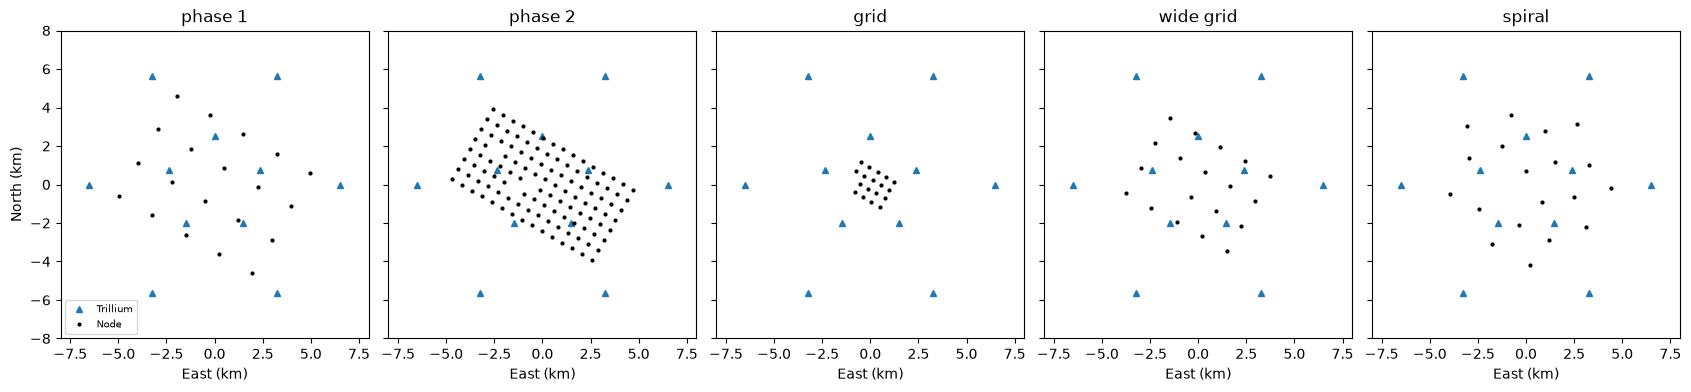

In [9]:
# --- Map of each design ---
show = {"phase 1": designs["phased"][0]["stations"],
        "phase 2": sum((ph["stations"] for ph in designs["phased"][1:]), []),
        **{n: designs[n][0]["stations"] for n in static}}

with plt.style.context("default"):
    fig, axs = plt.subplots(1, len(show), figsize=(3.4 * len(show), 3.6), sharex=True, sharey=True)
    for ax, (name, ids) in zip(axs, show.items()):
        ax.plot(stations.x[trill], stations.y[trill], "^", color="tab:blue", ms=5, label="Trillium")
        ax.plot(stations.x[existing], stations.y[existing], "s", color="tab:red", ms=4, label="Mercury (existing)")
        ax.plot(stations.x[ids], stations.y[ids], ".", color="k", ms=4, label="Node")
        ax.set(title=name, aspect="equal", xlim=(-12, 12), ylim=(-12, 12), xlabel="East (km)")
    axs[0].set_ylabel("North (km)")
    axs[0].legend(loc="lower left", fontsize=7)
    plt.tight_layout()
    plt.show()